In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

from src import models as M, evaluate as E, features as F
cfg, splits, feats = M.load_data()
tr, va, te = splits["train"], splits["val"], splits["test"]
res = E.results_table()
reg = M.load_registry()
naive = res.set_index("model").loc[E.NAIVE_NAME]
print(f"test rows: {len(te):,} district-weeks ({te.target_date.min().date()} to {te.target_date.max().date()}), "
      f"of which {E.outbreak_mask(te).mean():.1%} are outbreak weeks")

test rows: 4,854 district-weeks (2022-12-31 to 2026-08-24), of which 55.2% are outbreak weeks


In [2]:
cols = ["model", "family", "val_MAE", "MAE", "RMSE", "R2", "sMAPE", "MAE_vs_naive_pct", "RMSE_vs_naive_pct",
        "MAE_normal", "MAE_outbreak", "train_time_s"]
res[cols].round(3)

,model,family,val_MAE,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,RMSE_vs_naive_pct,MAE_normal,MAE_outbreak,train_time_s
0,Naive (last week),Baseline,11.547,14.949,37.586,0.867,46.210,0.000,0.000,7.432,21.062,0.00
1,Seasonal naive (last year),Baseline,20.114,37.753,95.695,0.140,79.931,-152.540,-154.600,17.630,54.118,0.00
2,Extra Trees,Bagging,10.340,14.506,39.089,0.856,43.813,2.963,-3.997,6.199,21.262,4.98
3,Random Forest,Bagging,10.393,14.520,37.472,0.868,44.349,2.874,0.304,6.073,21.389,8.49
4,Bagging (Decision Trees),Bagging,10.449,14.701,38.281,0.862,44.465,1.659,-1.848,6.031,21.752,6.69
5,Gradient Boosting,Boosting,10.430,15.447,43.010,0.826,43.936,-3.327,-14.429,5.894,23.216,4.09
6,CatBoost,Boosting,10.562,15.714,44.105,0.817,44.693,-5.115,-17.343,6.139,23.501,0.60
7,AdaBoost,Boosting,10.484,16.021,47.361,0.789,45.136,-7.169,-26.006,6.327,23.904,1.74
8,XGBoost,Boosting,10.442,16.508,51.886,0.747,44.382,-10.425,-38.045,5.926,25.113,0.30
9,LightGBM,Boosting,10.576,18.593,50.949,0.756,46.669,-24.376,-35.553,5.983,28.849,0.48


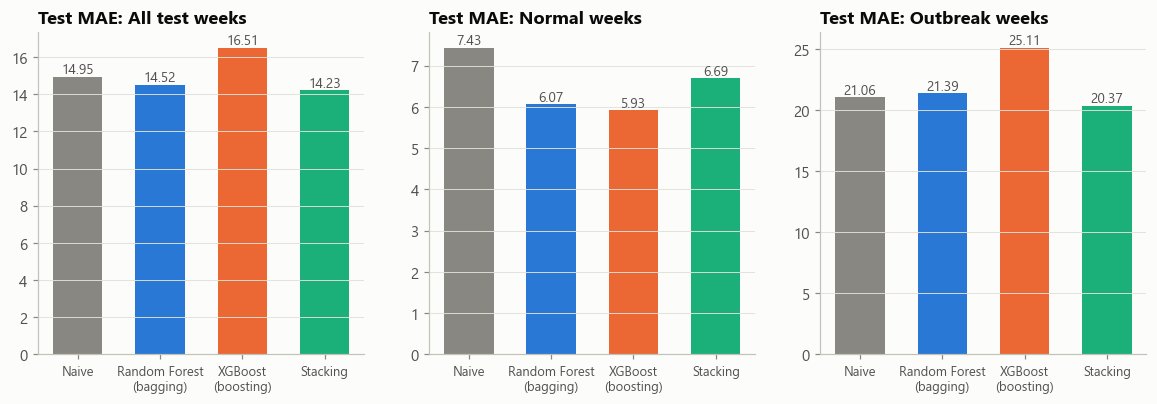

,family,MAE,RMSE,R2,sMAPE,MAE_vs_naive_pct,MAE_normal,MAE_outbreak,val_MAE,train_time_s
model,,,,,,,,,,
Naive (last week),Baseline,14.949,37.586,0.867,46.210,0.000,7.432,21.062,11.547,0.00
Random Forest,Bagging,14.520,37.472,0.868,44.349,2.874,6.073,21.389,10.393,8.49
XGBoost,Boosting,16.508,51.886,0.747,44.382,-10.425,5.926,25.113,10.442,0.30
Stacking (RF+XGB+LGBM+Cat -> Ridge),Stacking,14.234,36.884,0.872,43.334,4.784,6.692,20.367,10.455,27.46


In [3]:
CORE = {"Bagging": "Random Forest", "Boosting": "XGBoost", "Stacking": "Stacking (RF+XGB+LGBM+Cat -> Ridge)"}
core_cols = ["family", "MAE", "RMSE", "R2", "sMAPE", "MAE_vs_naive_pct", "MAE_normal", "MAE_outbreak", "val_MAE", "train_time_s"]
core = res.set_index("model").loc[[E.NAIVE_NAME] + list(CORE.values()), core_cols]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
names = [E.NAIVE_NAME] + list(CORE.values())
short = ["Naive", "Random Forest\n(bagging)", "XGBoost\n(boosting)", "Stacking"]
colors = [viz.FAMILY_COLORS[f] for f in core.family]
for ax, col, title in [(axes[0], "MAE", "All test weeks"), (axes[1], "MAE_normal", "Normal weeks"),
                       (axes[2], "MAE_outbreak", "Outbreak weeks")]:
    ax.bar(short, core[col].values, color=colors, width=0.6)
    for i, v in enumerate(core[col].values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=viz.INK_2)
    ax.set_title(f"Test MAE: {title}"); ax.tick_params(axis="x", labelsize=8.5)
viz.save(fig, "core_bagging_boosting_stacking"); plt.show()
core.round(3)

In [4]:
models_only = res[res.family != "Baseline"]
family_best = models_only.sort_values("val_MAE").groupby("family", sort=False).head(1).set_index("family")
family_best = family_best.loc[[f for f in E.FAMILY_ORDER if f in family_best.index]]
overall = models_only.sort_values("val_MAE").iloc[0]
test_best = models_only.sort_values("MAE").iloc[0]
display(family_best[["model", "val_MAE", "MAE", "RMSE", "MAE_vs_naive_pct", "MAE_outbreak"]].round(3))
print(f"OVERALL WINNER (validation): {overall.model}  ->  test MAE {overall.MAE:.2f} "
      f"({overall.MAE_vs_naive_pct:+.1f}% vs naive), RMSE {overall.RMSE:.2f} ({overall.RMSE_vs_naive_pct:+.1f}%)")
print(f"best on test:                {test_best.model}  ->  test MAE {test_best.MAE:.2f} ({test_best.MAE_vs_naive_pct:+.1f}% vs naive)")
rank_corr = models_only[["val_MAE", "MAE"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation between validation and test MAE across models: {rank_corr:.2f}")

,model,val_MAE,MAE,RMSE,MAE_vs_naive_pct,MAE_outbreak
family,,,,,,
Bagging,Extra Trees,10.340,14.506,39.089,2.963,21.262
Boosting,Gradient Boosting,10.430,15.447,43.010,-3.327,23.216
Stacking,"Voting (RF+XGB+LGBM+Cat, mean)",10.407,15.610,43.194,-4.421,23.533
Neural net,ANN (MLP),10.943,17.440,65.867,-16.664,26.020
Hybrid,Hybrid RF+ANN (weighted avg),10.361,14.190,36.894,5.077,20.847


OVERALL WINNER (validation): Extra Trees  ->  test MAE 14.51 (+3.0% vs naive), RMSE 39.09 (-4.0%)
best on test:                Hybrid RF+ANN (weighted avg)  ->  test MAE 14.19 (+5.1% vs naive)
Spearman rank correlation between validation and test MAE across models: 0.74


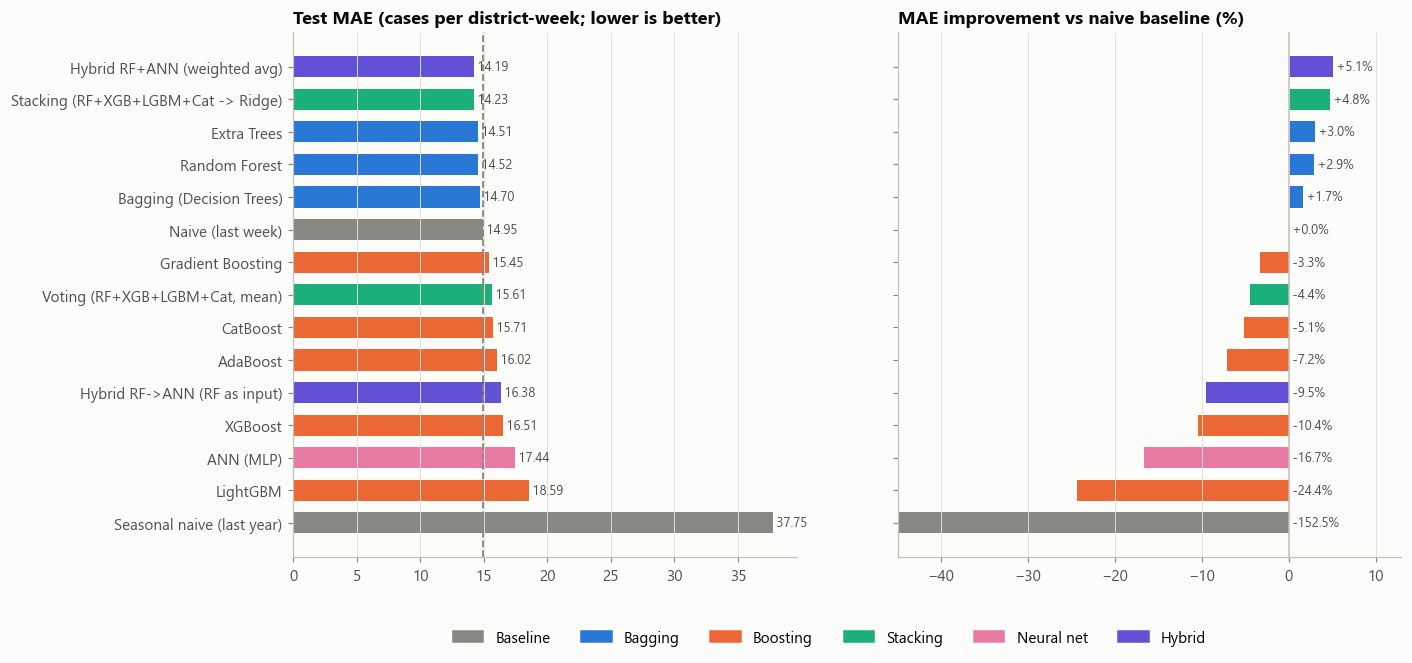

In [5]:
r = res.sort_values("MAE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), sharey=True)
colors = [viz.FAMILY_COLORS[f] for f in r.family]
axes[0].barh(r.model, r.MAE, color=colors, height=0.65)
axes[0].axvline(naive.MAE, color=viz.MUTED, ls="--", lw=1.2)
axes[0].set_title("Test MAE (cases per district-week; lower is better)")
for i, v in enumerate(r.MAE): axes[0].text(v, i, f" {v:.2f}", va="center", fontsize=8.5, color=viz.INK_2)
axes[1].barh(r.model, r.MAE_vs_naive_pct, color=colors, height=0.65)
axes[1].axvline(0, color=viz.AXIS, lw=1)
axes[1].set_title("MAE improvement vs naive baseline (%)")
for i, v in enumerate(r.MAE_vs_naive_pct): axes[1].text(max(v, 0), i, f" {v:+.1f}%", va="center", fontsize=8.5, color=viz.INK_2)
axes[1].set_xlim(left=max(r.MAE_vs_naive_pct.min(), -40) - 5)
for ax in axes: ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for f, c in viz.FAMILY_COLORS.items() if f in set(r.family)]
fig.legend(handles, [f for f in viz.FAMILY_COLORS if f in set(r.family)], ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.04))
viz.save(fig, "final_metrics_by_family"); plt.show()

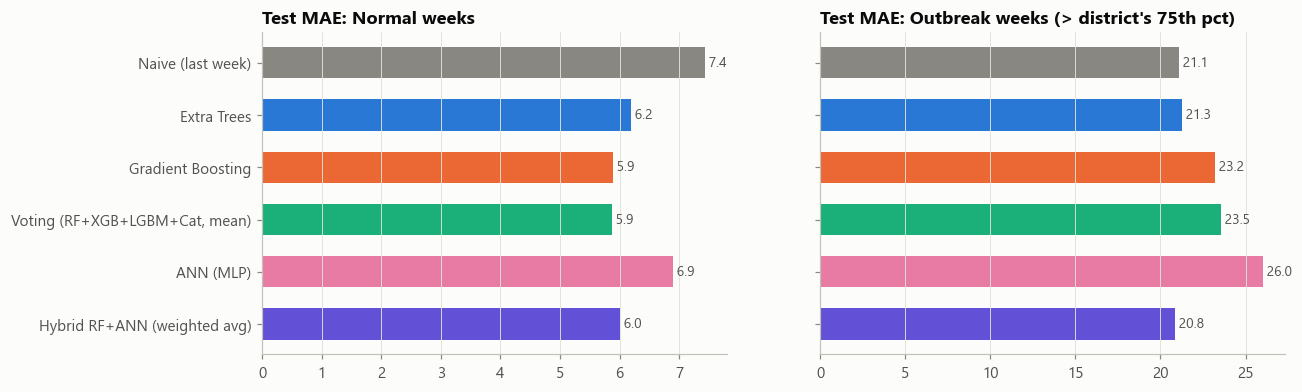

,family,MAE_normal,MAE_outbreak,ratio
model,,,,
Naive (last week),Baseline,7.43,21.06,2.83
Extra Trees,Bagging,6.20,21.26,3.43
Gradient Boosting,Boosting,5.89,23.22,3.94
"Voting (RF+XGB+LGBM+Cat, mean)",Stacking,5.87,23.53,4.01
ANN (MLP),Neural net,6.89,26.02,3.78
Hybrid RF+ANN (weighted avg),Hybrid,6.00,20.85,3.47


In [6]:
show = [E.NAIVE_NAME] + list(family_best.model)
rr = res.set_index("model").loc[show]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, title in [(axes[0], "MAE_normal", "Normal weeks"), (axes[1], "MAE_outbreak", "Outbreak weeks (> district's 75th pct)")]:
    ax.barh(show[::-1], rr[col].values[::-1], color=[viz.FAMILY_COLORS[f] for f in rr.family][::-1], height=0.6)
    for i, v in enumerate(rr[col].values[::-1]): ax.text(v, i, f" {v:.1f}", va="center", fontsize=9, color=viz.INK_2)
    ax.set_title(f"Test MAE: {title}"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
viz.save(fig, "final_normal_vs_outbreak"); plt.show()
rr[["family", "MAE_normal", "MAE_outbreak"]].assign(ratio=lambda d: d.MAE_outbreak / d.MAE_normal).round(2)

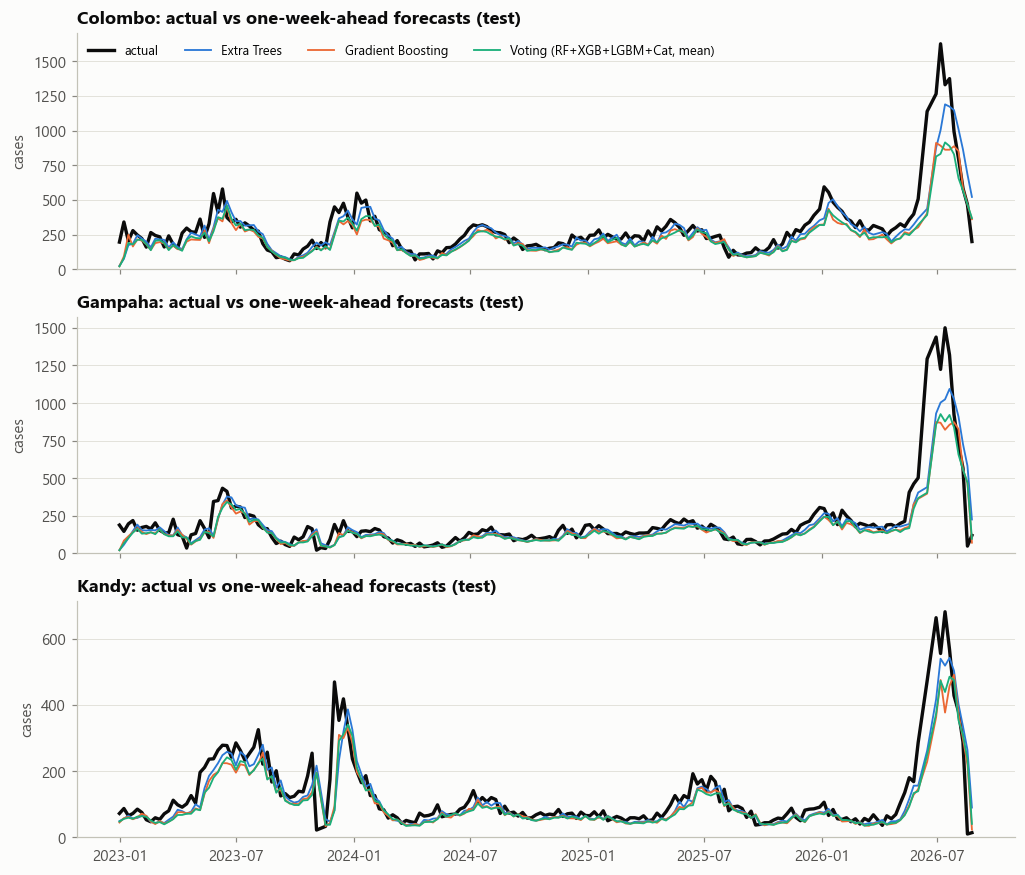

In [7]:
tp = E.load_predictions("test")
lines = [(family_best.loc["Bagging", "model"], viz.SERIES[0]), (family_best.loc["Boosting", "model"], viz.SERIES[1]),
         (family_best.loc["Stacking", "model"], viz.SERIES[2])]
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True)
for ax, dist in zip(axes, ["Colombo", "Gampaha", "Kandy"]):
    p = tp[tp.district == dist].sort_values("target_date")
    ax.plot(p.target_date, p.target, color=viz.INK, lw=2.2, label="actual")
    for m, c in lines:
        ax.plot(p.target_date, p[m], color=c, lw=1.2, label=m)
    ax.set_title(f"{dist}: actual vs one-week-ahead forecasts (test)"); ax.set_ylabel("cases"); ax.set_ylim(0)
axes[0].legend(ncol=4, loc="upper left", fontsize=8.5)
viz.save(fig, "final_actual_vs_predicted"); plt.show()

In [8]:
h2h = ["Random Forest", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost"]
hh = res.set_index("model").loc[h2h, ["val_MAE", "MAE", "RMSE", "R2", "MAE_normal", "MAE_outbreak", "MAE_vs_naive_pct", "train_time_s"]]
hh.round(3)

,val_MAE,MAE,RMSE,R2,MAE_normal,MAE_outbreak,MAE_vs_naive_pct,train_time_s
model,,,,,,,,
Random Forest,10.393,14.520,37.472,0.868,6.073,21.389,2.874,8.49
Gradient Boosting,10.430,15.447,43.010,0.826,5.894,23.216,-3.327,4.09
XGBoost,10.442,16.508,51.886,0.747,5.926,25.113,-10.425,0.30
LightGBM,10.576,18.593,50.949,0.756,5.983,28.849,-24.376,0.48
CatBoost,10.562,15.714,44.105,0.817,6.139,23.501,-5.115,0.60


In [9]:
# A regression tree predicts the average of training targets in a leaf, so a forest can never predict
# more than the largest value it saw in training (per similar situation). Boosting adds up many trees, so it can in
# principle exceed it, but only slightly. We check how often the test period goes above each district's training maximum.
train_max = tr.groupby("district").target.max()
above = te.target.to_numpy() > te.district.map(train_max).to_numpy()
print(f"test district-weeks above that district's 2007-2021 maximum: {above.sum()} ({above.mean():.1%})")
print("districts affected:", te[above].district.value_counts().to_dict())

ob = E.outbreak_mask(te)
key = [E.NAIVE_NAME] + list(family_best.model)
tp_al = tp.set_index(["district", "target_date"]).loc[list(zip(te.district, te.target_date))]
bias = pd.DataFrame({m: {"mean error, normal weeks": (tp_al[m].to_numpy() - te.target.to_numpy())[~ob].mean(),
                         "mean error, outbreak weeks": (tp_al[m].to_numpy() - te.target.to_numpy())[ob].mean(),
                         "max prediction": tp_al[m].max(), "max actual": te.target.max()} for m in key}).T
print("mean error = prediction - actual (negative = under-prediction)")
bias.round(2)

test district-weeks above that district's 2007-2021 maximum: 17 (0.4%)
districts affected: {'Hambantota': 4, 'Galle': 3, 'Matara': 3, 'Kilinochchi': 2, 'Mullaitivu': 2, 'Monaragala': 1, 'Kalutara': 1, 'Nuwara Eliya': 1}
mean error = prediction - actual (negative = under-prediction)


,"mean error, normal weeks","mean error, outbreak weeks",max prediction,max actual
Naive (last week),3.91,-3.27,1625.00,1625.0
Extra Trees,2.19,-12.44,1188.77,1625.0
Gradient Boosting,1.24,-18.28,910.74,1625.0
"Voting (RF+XGB+LGBM+Cat, mean)",1.16,-18.64,926.48,1625.0
ANN (MLP),3.53,-1.00,3706.15,1625.0
Hybrid RF+ANN (weighted avg),2.14,-9.65,1884.61,1625.0


In [10]:
# Colombo in the 2026 outbreak: how close do the models get to the peak?
p = tp[(tp.district == "Colombo") & (tp.target_date >= "2026-04-01")].sort_values("target_date")
print("Colombo 2007-2021 training maximum:", int(train_max["Colombo"]))
peak = p.loc[p.target.idxmax()]
print(f"2026 peak week {peak.target_date.date()}: actual {peak.target:.0f}")
for m in key:
    print(f"   {m:40s} forecast {peak[m]:7.1f}  ({100*(peak[m]-peak.target)/peak.target:+.0f}%)")

Colombo 2007-2021 training maximum: 1972
2026 peak week 2026-07-06: actual 1625
   Naive (last week)                        forecast  1264.0  (-22%)
   Extra Trees                              forecast  1002.8  (-38%)
   Gradient Boosting                        forecast   890.8  (-45%)
   Voting (RF+XGB+LGBM+Cat, mean)           forecast   832.1  (-49%)
   ANN (MLP)                                forecast  2227.4  (+37%)
   Hybrid RF+ANN (weighted avg)             forecast  1420.0  (-13%)


In [11]:
rows = []
for name in ["Random Forest", "XGBoost", "LightGBM"]:
    params, rounds = M.load_best_params(name)
    for use_log in [True, False]:
        if use_log:
            pipe = M.build_final(name, params, cfg, n_rounds=rounds)
        else:   # without the log wrapper the regressor sits at "model__" instead of "model__regressor__"
            pipe = M.make_pipeline(M.CATALOGUE[name][1](), dict(cfg, use_log_target=False))
            pipe.set_params(**{k.replace(M.P, "model__"): v for k, v in params.items()})
            if rounds: pipe.set_params(model__n_estimators=rounds)
        pipe.fit(tr[feats], tr.target)
        p = np.clip(pipe.predict(te[feats]), 0, None)
        err = p - te.target.to_numpy()
        rows.append({"model": name, "target": "log1p" if use_log else "raw",
                     "val_MAE": E.regression_metrics(va.target, pipe.predict(va[feats]))["MAE"],
                     "test_MAE": np.abs(err).mean(), "MAE_normal": np.abs(err)[~ob].mean(),
                     "MAE_outbreak": np.abs(err)[ob].mean(), "mean_error_outbreak": err[ob].mean(),
                     "mean_error_normal": err[~ob].mean()})
log_vs_raw = pd.DataFrame(rows)
log_vs_raw.round(3)

,model,target,val_MAE,test_MAE,MAE_normal,MAE_outbreak,mean_error_outbreak,mean_error_normal
0,Random Forest,log1p,10.393,14.520,6.073,21.389,-11.813,1.796
1,Random Forest,raw,10.670,14.543,7.546,20.232,-2.927,5.305
2,XGBoost,log1p,10.442,16.508,5.926,25.113,-20.438,1.243
3,XGBoost,raw,10.671,14.370,7.415,20.025,-6.296,4.976
4,LightGBM,log1p,10.576,18.593,5.983,28.849,-26.234,-0.187
5,LightGBM,raw,10.769,14.602,7.334,20.513,-6.917,4.936


SHAP model (best single tree ensemble by validation): Extra Trees | values are on the log1p scale


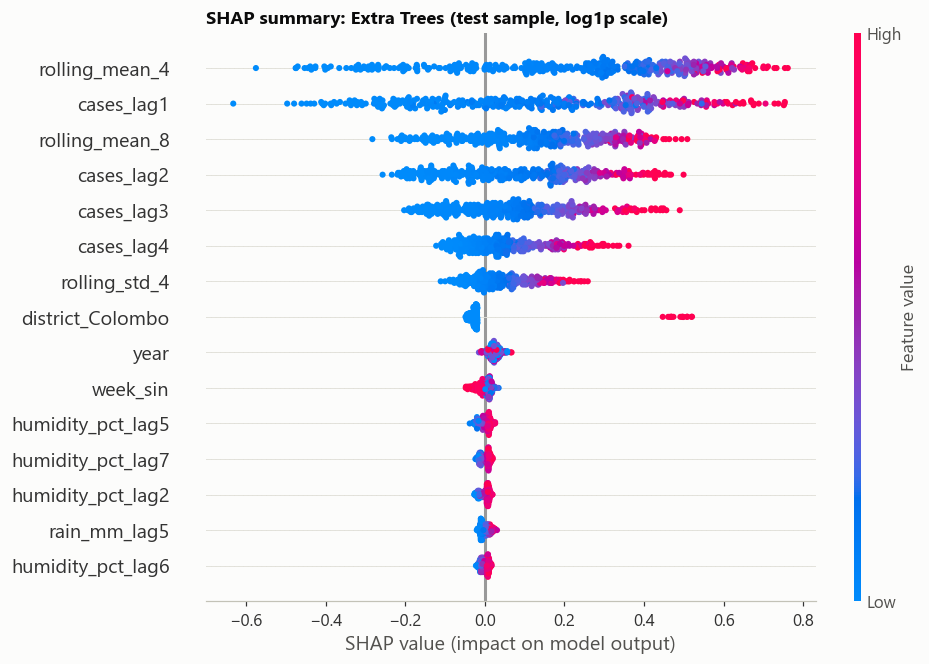

share of mean |SHAP| by feature group: {'recent cases (lags & rolling)': 0.849, 'weather (lags 1-8)': 0.08, 'district': 0.041, 'calendar': 0.03, 'was-missing flags': 0.0}
weather mean |SHAP| by lag (weeks): {1: 0.016, 2: 0.0171, 3: 0.0093, 4: 0.0094, 5: 0.0208, 6: 0.0143, 7: 0.0184, 8: 0.0115}


rolling_mean_4      0.3384
cases_lag1          0.2724
rolling_mean_8      0.1795
cases_lag2          0.1616
cases_lag3          0.1350
cases_lag4          0.0837
rolling_std_4       0.0660
district_Colombo    0.0436
year                0.0242
week_sin            0.0130
dtype: float64

In [12]:
import shap
single = res[res.family.isin(["Bagging", "Boosting"])].sort_values("val_MAE")
shap_model_name = next(m for m in single.model if any(e["name"] == m for e in reg.values()))
pipe = M.load_predictor(shap_model_name)
prep, inner = pipe.named_steps["prep"], pipe.named_steps["model"].regressor_
names = prep.get_feature_names_out()
sample = te.sample(400 if "Forest" in shap_model_name or "Trees" in shap_model_name else 1500, random_state=config.RANDOM_STATE)
Xs = pd.DataFrame(prep.transform(sample[feats]), columns=names)
explainer = shap.TreeExplainer(inner)
sv = explainer.shap_values(Xs)
print("SHAP model (best single tree ensemble by validation):", shap_model_name, "| values are on the log1p scale")
shap.summary_plot(sv, Xs, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP summary: {shap_model_name} (test sample, log1p scale)", loc="left", fontsize=12, fontweight="bold")
viz.save(plt.gcf(), "shap_summary"); plt.show()

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=names)
def group(n):
    if n.startswith(("cases", "rolling")): return "recent cases (lags & rolling)"
    if n.startswith(("rain", "temp", "humid")): return "weather (lags 1-8)"
    if n.startswith("district"): return "district"
    if n in ("week_sin", "week_cos", "year"): return "calendar"
    return "was-missing flags"
shap_groups = (mean_abs.groupby(group).sum() / mean_abs.sum()).sort_values(ascending=False)
print("share of mean |SHAP| by feature group:", shap_groups.round(3).to_dict())
weather_lag = mean_abs[[n for n in names if n.startswith(("rain", "humid", "temp"))]]
by_lag = weather_lag.groupby(lambda n: int(n.split("lag")[1])).sum()
print("weather mean |SHAP| by lag (weeks):", by_lag.round(4).to_dict())
mean_abs.sort_values(ascending=False).head(10).round(4)

In [13]:
import json
from datetime import date

vp = E.load_predictions("val")
BASE = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
_c = vp[BASE].sub(vp.target, axis=0).corr().to_numpy()
base_corr = _c[np.triu_indices(len(BASE), 1)]           # pairwise validation-error correlations

bp = json.loads((config.MODELS_DIR / "best_params.json").read_text())
cv_rank = pd.Series({m: v["cv_mae"] for m, v in bp.items() if v.get("cv_mae") is not None}).sort_values()
arima = pd.read_csv(config.MODELS_DIR / "hybrid_arima_results.csv")
nat = arima[arima.series == "National"].set_index("model")
col = arima[arima.series == "Colombo"].set_index("model")
R = res.set_index("model")
deployed = overall.model            # rule fixed before seeing test results: lowest validation MAE
w_rf = reg["rf_ann_weighted"]["weight_rf"]
bag, boost = res[res.family == "Bagging"], res[res.family == "Boosting"]
stack_r, hyb_r, ann_r = R.loc["Stacking (RF+XGB+LGBM+Cat -> Ridge)"], R.loc["Hybrid RF+ANN (weighted avg)"], R.loc["ANN (MLP)"]
lr = log_vs_raw.set_index(["model", "target"])
meta_w = pd.Series(reg["stacking"]["meta_weights"])


def row(m):
    r = R.loc[m]
    return {"model": m, "family": r.family, "val_MAE": round(r.val_MAE, 3), "MAE": round(r.MAE, 3),
            "RMSE": round(r.RMSE, 3), "MAE_vs_naive_pct": round(r.MAE_vs_naive_pct, 2),
            "MAE_normal": round(r.MAE_normal, 3), "MAE_outbreak": round(r.MAE_outbreak, 3)}


key_findings = [
    f"Next week usually looks like this week, so the simple rule 'next week = this week' is a tough benchmark "
    f"(test MAE {naive.MAE:.2f} cases per region-week). Recent case counts carry about "
    f"{shap_groups.get('recent cases (lags & rolling)', 0):.0%} of the model's reasoning; weather about "
    f"{shap_groups.get('weather (lags 1-8)', 0):.0%}, strongest for rain and humidity 5 and 7 weeks earlier.",
    f"Bagging was the most reliable single family: Random Forest and Extra Trees beat the naive rule by about "
    f"{bag.MAE_vs_naive_pct.max():.0f}% (MAE {bag.MAE.min():.2f}), being "
    f"{100 * (1 - bag.MAE_normal.min() / naive.MAE_normal):.0f}% more accurate in normal weeks while staying about "
    f"level with naive in outbreak weeks.",
    f"Boosting was the most accurate in calm weeks (normal-week MAE {boost.MAE_normal.min():.2f}-{boost.MAE_normal.max():.2f}) "
    f"but under-predicted the 2023-2026 surges, ending {-boost.MAE_vs_naive_pct.max():.0f}-{-boost.MAE_vs_naive_pct.min():.0f}% "
    f"worse than naive. A test showed why: trained on the log of cases, LightGBM scored MAE "
    f"{lr.loc[('LightGBM', 'log1p'), 'test_MAE']:.2f}; trained on raw cases it scored "
    f"{lr.loc[('LightGBM', 'raw'), 'test_MAE']:.2f}, because the log transform pulls forecasts of big outbreaks down.",
    f"Stacking improved on every single model on test (MAE {stack_r.MAE:.2f}, {stack_r.MAE_vs_naive_pct:+.1f}% vs naive) "
    f"even though the base models' errors were {base_corr.mean():.0%} correlated: its meta-learner weights add up to "
    f"{meta_w.sum():.2f}, slightly scaling forecasts up, which offsets the trees' tendency to under-forecast outbreaks. "
    f"Simple averaging (voting) did not ({R.loc['Voting (RF+XGB+LGBM+Cat, mean)', 'MAE_vs_naive_pct']:+.1f}%).",
    f"The best test result came from a hybrid: {w_rf:.0%} Random Forest + {1 - w_rf:.0%} neural network "
    f"(MAE {hyb_r.MAE:.2f}, {hyb_r.MAE_vs_naive_pct:+.1f}% vs naive). The two make opposite mistakes in outbreaks "
    f"(the forest forecasts too low, the network can over-shoot), so blending them cancels part of the error. "
    f"SARIMA + Random Forest on the national total also beat naive ({nat.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%) "
    f"while each part alone did not.",
]

hybrid_notes = [
    f"RF + SARIMA, national weekly total: hybrid MAE {nat.loc['Hybrid RF+SARIMA', 'MAE']:.0f} cases/week vs naive "
    f"{nat.loc['Naive (last week)', 'MAE']:.0f} ({nat.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%); SARIMA alone "
    f"{nat.loc['SARIMA alone', 'MAE_vs_naive_pct']:+.1f}%, RF alone {nat.loc['RF alone', 'MAE_vs_naive_pct']:+.1f}%. "
    f"SARIMA supplies the seasonal level, the forest corrects what SARIMA misses.",
    f"RF + SARIMA, Colombo: nothing beat naive (hybrid {col.loc['Hybrid RF+SARIMA', 'MAE_vs_naive_pct']:+.1f}%); "
    f"Colombo's sudden 2026 surge was faster than any model could follow one week ahead.",
    f"RF + ANN weighted average: weight {w_rf:.2f} on the forest, tuned on 2022. Test MAE {hyb_r.MAE:.2f} "
    f"({hyb_r.MAE_vs_naive_pct:+.1f}% vs naive), the best of all models on test; the ANN alone scored "
    f"{ann_r.MAE_vs_naive_pct:+.1f}%.",
    "RF -> ANN (forest forecast as an extra network input): "
    f"{R.loc['Hybrid RF->ANN (RF as input)', 'MAE_vs_naive_pct']:+.1f}% vs naive; feeding one model into the other "
    f"amplified errors in outbreaks instead of cancelling them.",
]

# ---- core comparison required by the brief: one model per ensemble strategy
rf_r, xgb_r = R.loc["Random Forest"], R.loc["XGBoost"]
core_ranked = sorted(CORE.items(), key=lambda kv: R.loc[kv[1], "MAE"])
CORE_SHORT = {"Bagging": "Random Forest", "Boosting": "XGBoost", "Stacking": "RF+XGB+LGBM+CatBoost -> Ridge"}
xgb_raw, xgb_log = lr.loc[("XGBoost", "raw")], lr.loc[("XGBoost", "log1p")]
core_explanation = [
    "Ranking on the same test weeks: " + ", then ".join(
        f"{fam} ({CORE_SHORT[fam]}: MAE {R.loc[m, 'MAE']:.2f}, {R.loc[m, 'MAE_vs_naive_pct']:+.1f}% vs naive)"
        for fam, m in core_ranked) + f". The naive rule scores {naive.MAE:.2f}.",
    f"Bagging (Random Forest) averages hundreds of deep trees, which removes noise (lower variance): it is "
    f"{100 * (1 - rf_r.MAE_normal / naive.MAE_normal):.0f}% more accurate than naive in normal weeks "
    f"({rf_r.MAE_normal:.2f} vs {naive.MAE_normal:.2f}) and close to naive in outbreak weeks "
    f"({rf_r.MAE_outbreak:.2f} vs {naive.MAE_outbreak:.2f}).",
    f"Boosting (XGBoost) adds shallow trees one at a time to remove bias. It fits calm weeks best "
    f"(normal-week MAE {xgb_r.MAE_normal:.2f}) but under-forecasts surges (outbreak-week MAE {xgb_r.MAE_outbreak:.2f}, "
    f"average error {xgb_log.mean_error_outbreak:+.1f} cases). The cause is the log-cases target, not boosting itself: "
    f"the same XGBoost trained on raw cases scores MAE {xgb_raw.test_MAE:.2f} "
    f"({E.improvement(xgb_raw.test_MAE, naive.MAE):+.1f}% vs naive) with an outbreak error of only "
    f"{xgb_raw.mean_error_outbreak:+.1f}. Log-cases was chosen because it won on the calm 2022 validation year.",
    f"Stacking learns how to combine Random Forest, XGBoost, LightGBM and CatBoost. Their errors are "
    f"{base_corr.mean():.0%} correlated, so it cannot gain much from diversity, but its meta-learner weights sum to "
    f"{meta_w.sum():.2f}, lifting forecasts slightly and correcting part of the shared under-forecast "
    f"(outbreak-week MAE {stack_r.MAE_outbreak:.2f}, the lowest of the three).",
]

family_text = {
    "Baseline": "Simple rules with no learning, e.g. 'next week = this week'. Every model must beat these to be useful.",
    "Bagging": "Many deep decision trees, each trained on a random resample of the data, are averaged. "
               "Averaging cancels individual trees' mistakes (reduces variance), giving stable forecasts.",
    "Boosting": "Small trees are added one after another, each fixing the errors of those before it (reduces bias). "
                "Very accurate in familiar conditions, but here it was too cautious in sudden surges.",
    "Stacking": "Several different models forecast and a final 'manager' model learns how much to trust each. "
                "It helps most when the models make different mistakes.",
    "Neural net": "A small artificial neural network (MLP) that learns smooth patterns from scaled inputs. "
                  "Unlike trees it can forecast values above anything it has seen, which can over-shoot.",
    "Hybrid": "Two different kinds of model combined: a seasonal time-series model (SARIMA) plus a Random Forest that "
              "corrects its errors, or a Random Forest blended with a neural network.",
}

summary = {
    "generated": str(date.today()),
    "selection_rule": "Lowest validation MAE (2022); test results are reported only.",
    "test_period": [str(te.target_date.min().date()), str(te.target_date.max().date())],
    "n_test_rows": int(len(te)),
    "outbreak_week_share": round(float(E.outbreak_mask(te).mean()), 4),
    "naive": row(E.NAIVE_NAME),
    "winner_per_family": {f: row(family_best.loc[f, "model"]) for f in family_best.index},
    "overall_winner_validation": row(overall.model),
    "best_on_test": row(test_best.model),
    "deployed_model": deployed,
    "core_comparison": {fam: row(m) for fam, m in CORE.items()},
    "core_explanation": core_explanation,
    "cv_mae_ranking_2007_2021": cv_rank.round(3).to_dict(),
    "validation_test_rank_correlation": round(float(rank_corr), 3),
    "stacking_error_correlation": round(float(base_corr.mean()), 4),
    "stacking_meta_weights": meta_w.round(4).to_dict(),
    "log_vs_raw_diagnostic": log_vs_raw.round(3).to_dict(orient="records"),
    "rf_sarima": arima.round(3).to_dict(orient="records"),
    "shap_group_share": shap_groups.round(4).to_dict(),
    "family_explanations": family_text,
    "key_findings": key_findings,
    "hybrid_notes": hybrid_notes,
    "why_best": (
        f"No single family dominated, so the answer has two parts. Among single model families, bagging (Random Forest / "
        f"Extra Trees) was the most reliable: averaging hundreds of deep trees keeps forecasts close to recent case levels "
        f"while removing noise, beating the naive rule by about {bag.MAE_vs_naive_pct.max():.0f}%. Overall, the best test "
        f"results came from combining models whose mistakes partly cancel: stacking ({stack_r.MAE_vs_naive_pct:+.1f}%) and "
        f"the Random Forest + neural network hybrid ({hyb_r.MAE_vs_naive_pct:+.1f}%). Boosting was best in calm weeks but "
        f"worst in outbreaks, because trained on log-cases it under-forecasts surges. The deployed model, {deployed}, "
        f"was chosen in advance by the 2022 validation error; 2022 was a calm year, so validation could not fully "
        f"separate the models' outbreak behaviour."),
}
(config.MODELS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
M.register("overall_best", deployed, next(e["file"] for e in reg.values() if e["name"] == deployed))
print("deployed model (validation rule):", deployed, "| best on test:", test_best.model)
print("time-series CV MAE ranking (2007-2021 folds):", cv_rank.round(3).to_dict())
for i, k in enumerate(key_findings, 1):
    print(f"{i}. {k}")
print("\nCore comparison (bagging vs boosting vs stacking):")
for k in core_explanation:
    print(" -", k)

deployed model (validation rule): Extra Trees | best on test: Hybrid RF+ANN (weighted avg)
time-series CV MAE ranking (2007-2021 folds): {'Random Forest': 13.56, 'Bagging (Decision Trees)': 13.653, 'CatBoost': 14.418, 'Gradient Boosting': 14.477, 'LightGBM': 14.577, 'XGBoost': 14.881, 'Extra Trees': 14.888, 'AdaBoost': 15.281}
1. Next week usually looks like this week, so the simple rule 'next week = this week' is a tough benchmark (test MAE 14.95 cases per region-week). Recent case counts carry about 85% of the model's reasoning; weather about 8%, strongest for rain and humidity 5 and 7 weeks earlier.
2. Bagging was the most reliable single family: Random Forest and Extra Trees beat the naive rule by about 3% (MAE 14.51), being 19% more accurate in normal weeks while staying about level with naive in outbreak weeks.
3. Boosting was the most accurate in calm weeks (normal-week MAE 5.89-6.33) but under-predicted the 2023-2026 surges, ending 3-24% worse than naive. A test showed why: tra